In [ ]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from scipy.stats import ks_2samp, mannwhitneyu, anderson_ksamp, shapiro
import seaborn as sns


from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [2]:
def get_hidden_layer_activations(model, X):
    """
    Extract activations from the hidden layer of an MLPClassifier.
    """

    if hasattr(X, 'values'):
        X = X.values
        
    # Get activations from the hidden layer
    hidden_activations = X.copy()
    
    # Apply the transformation through the first layer
    hidden_activations = hidden_activations @ model.coefs_[0] + model.intercepts_[0]
    
    # Apply the relu activation function
    hidden_activations = np.maximum(0, hidden_activations)

    return hidden_activations

In [3]:
def plot_embedded_with_nn(tsne_embedded, pca_embedded, nn_embedded, title=False):
    # Convert everything to numpy arrays
    if hasattr(tsne_embedded, 'values'):
        tsne_embedded = tsne_embedded.values
    if hasattr(pca_embedded, 'values'):
        pca_embedded = pca_embedded.values
    if hasattr(nn_embedded, 'values'):
        nn_embedded = nn_embedded.values
    
    fig = plt.figure(figsize=(20, 6))
    
    # Define colors for labels
    colors = {0: 'royalblue', 1: 'crimson'}
    labels = {0: 'Healthy', 1: 'Unhealthy'}
    
    # Plot unhealthy first (so healthy appears on top if overlapping)
    plot_order = [1, 0]  # Plot class 1 first, then class 0
    
    # --- t-SNE plot ---
    ax1 = fig.add_subplot(1, 3, 1, projection='3d')
    for label in plot_order:
        mask = y == label
        ax1.scatter(
            tsne_embedded[mask, 0],
            tsne_embedded[mask, 1],
            color=colors[label],
            label=f"{labels[label]} (n={mask.sum()})",
            alpha=0.6,
            s=50,
            edgecolors='black',
            linewidths=0.5
        )
    ax1.set_title("t-SNE (3D)", fontsize=12)
    ax1.set_xlabel("Dim 1")
    ax1.set_ylabel("Dim 2")
    ax1.set_zlabel("Dim 3")
    ax1.legend()
    
    # --- PCA plot ---
    ax2 = fig.add_subplot(1, 3, 2, projection='3d')
    for label in plot_order:
        mask = y == label
        ax2.scatter(
            pca_embedded[mask, 0],
            pca_embedded[mask, 1],
            color=colors[label],
            label=f"{labels[label]} (n={mask.sum()})",
            alpha=0.6,
            s=50,
            edgecolors='black',
            linewidths=0.5
        )
    ax2.set_title("PCA (3D)", fontsize=12)
    ax2.set_xlabel("PC 1")
    ax2.set_ylabel("PC 2")
    ax2.set_zlabel("PC 3")
    
    # --- Neural Network Hidden Layer plot ---
    ax3 = fig.add_subplot(1, 3, 3, projection='3d')
    for label in plot_order:
        mask = y == label
        ax3.scatter(
            nn_embedded[mask, 0],
            nn_embedded[mask, 1],
            color=colors[label],
            label=f"{labels[label]} (n={mask.sum()})",
            alpha=0.6,
            s=50,
            edgecolors='black',
            linewidths=0.5
        )
    ax3.set_title("Neural Network Hidden Layer (3D)", fontsize=12)
    ax3.set_xlabel("Neuron 1")
    ax3.set_ylabel("Neuron 2")
    ax3.set_zlabel("Neuron 3")
    
    # Add a single legend
    ax3.legend(
        loc='center left',
        bbox_to_anchor=(1.05, 0.9),
        title="Condition",
        frameon=False
    )
    
    if title:
        plt.suptitle(title, fontsize=13, y=1.01)
    
    plt.tight_layout()
    plt.show()

In [4]:
def plot_for_features(feature_set, title=False):
    # Train neural network with 3-neuron hidden layer (3d feature space)
    nn_model = MLPClassifier(
        hidden_layer_sizes=(3,),
        activation='relu',
        max_iter=10000,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.2
    )
    nn_model.fit(feature_set, y)
    
    # Get hidden layer activations
    nn_embedded = get_hidden_layer_activations(nn_model, feature_set)
    
    # Create visualizations (also use scaled data for consistency)
    tsne_embedded = TSNE(
        n_components=3, 
        learning_rate='auto', 
        init='random', 
        perplexity=3, 
        random_state=42
    ).fit_transform(feature_set)
    
    pca = PCA(n_components=3)
    pca_embedded = pca.fit_transform(feature_set)
    
    # Print model performance
    print(f"Training accuracy: {nn_model.score(feature_set, y):.3f}")
    
    # Plot all three
    plot_embedded_with_nn(
        tsne_embedded, 
        pca_embedded, 
        nn_embedded,
        title=title
    )

In [5]:
stage_1_df = pd.read_csv("data/stage_1.csv", index_col=0)
stage_2_df = pd.read_csv("data/stage_2.csv", index_col=0)

stage_1_df.drop(columns=["id"], inplace=True)
stage_2_df.drop(columns=["id"], inplace=True)

X_s1 = stage_1_df.drop(columns=["is_unhealthy"])
X_s2 = stage_2_df.drop(columns=["is_unhealthy"])
y = stage_1_df["is_unhealthy"]

base_features = [
    "hypertension", "early_rupture", "meconium", "induced", "no_progress",
    "is_male", "fetal_weight", "weeks", "is_first_birth", "age",
    "prev_birth", "normal_pres", "stage_1_percent", 
    "stage_1_normalized", "stage_2_normalized"
]

# Signal processing methods
preprocessing_methods = [
    "drop_long_then_autoencoder",
    "drop_long_then_interpolate",
    "drop_long_then_weighted_fill",
    "drop_zeros",
    "interpolate"
]

## Visualizing separatability using the full feature space

Training accuracy: 0.351


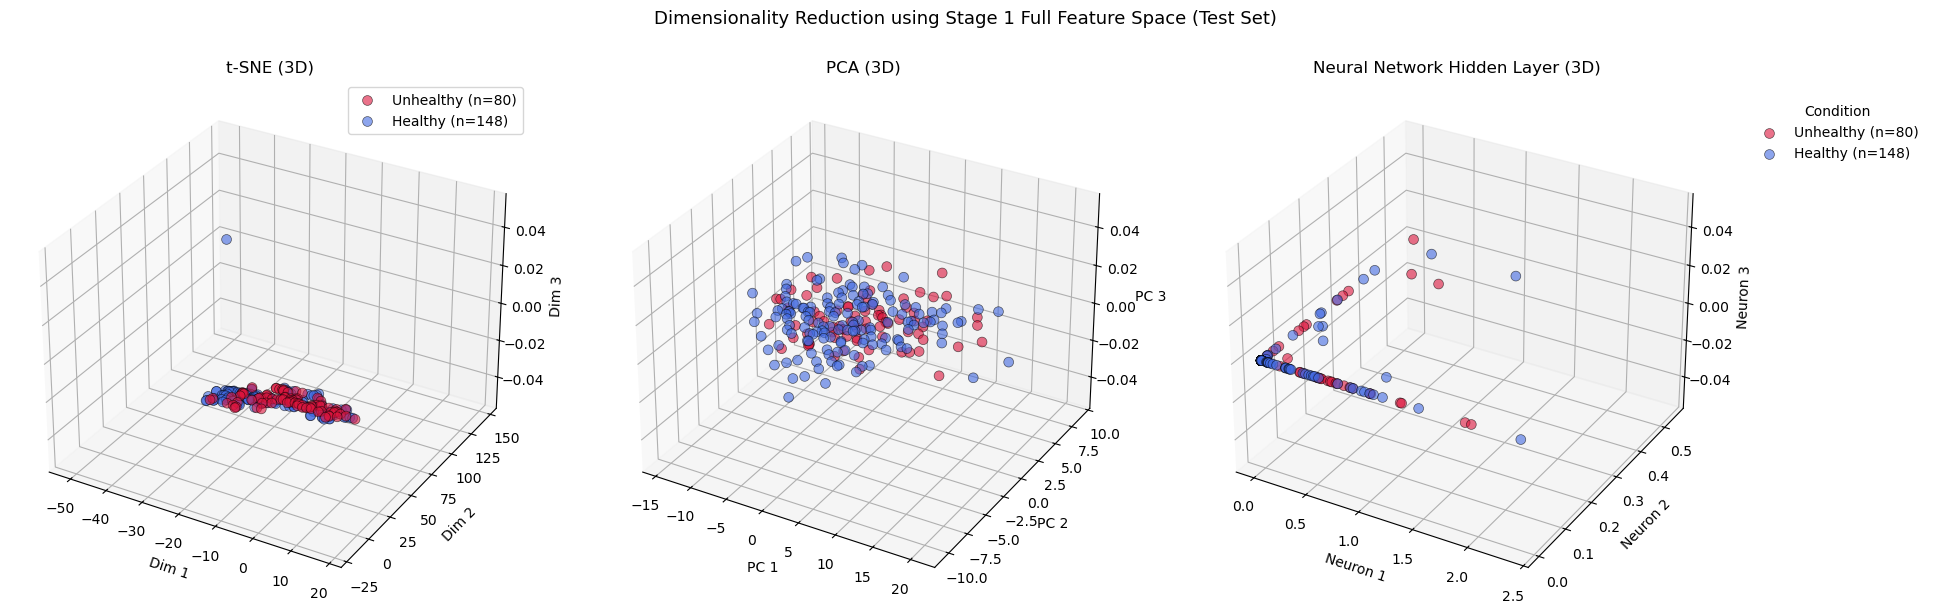

In [6]:
# stage 1
plot_for_features(X_s1, title="Dimensionality Reduction using Stage 1 Full Feature Space (Test Set)")

Training accuracy: 0.355


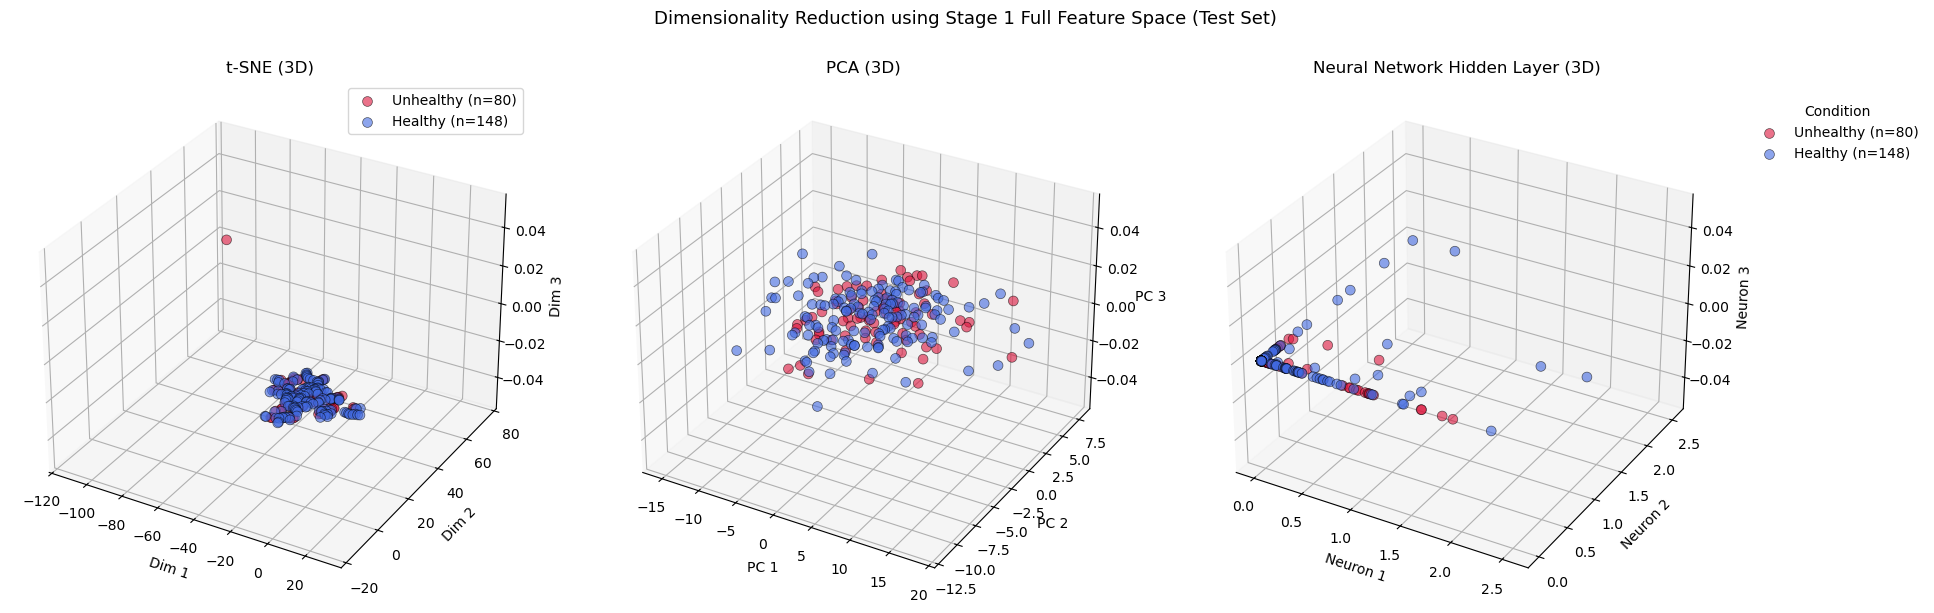

In [7]:
# stage 2
plot_for_features(X_s2, title="Dimensionality Reduction using Stage 1 Full Feature Space (Test Set)")

## Visualizing separatability using the Base Features (no features from signal)

Training accuracy: 0.360


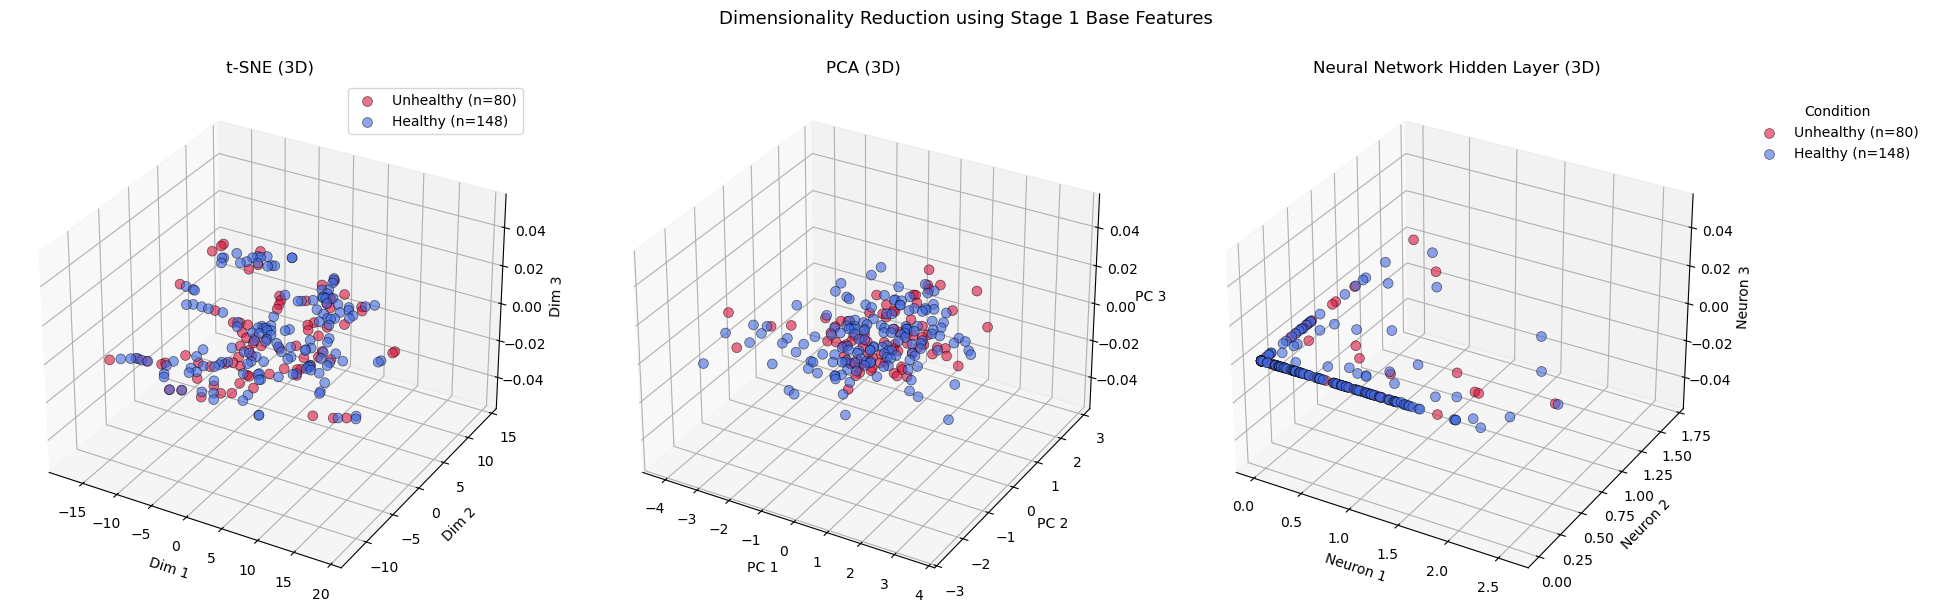

In [8]:
# Stage 1
plot_for_features(X_s1[base_features], title="Dimensionality Reduction using Stage 1 Base Features")

Training accuracy: 0.360


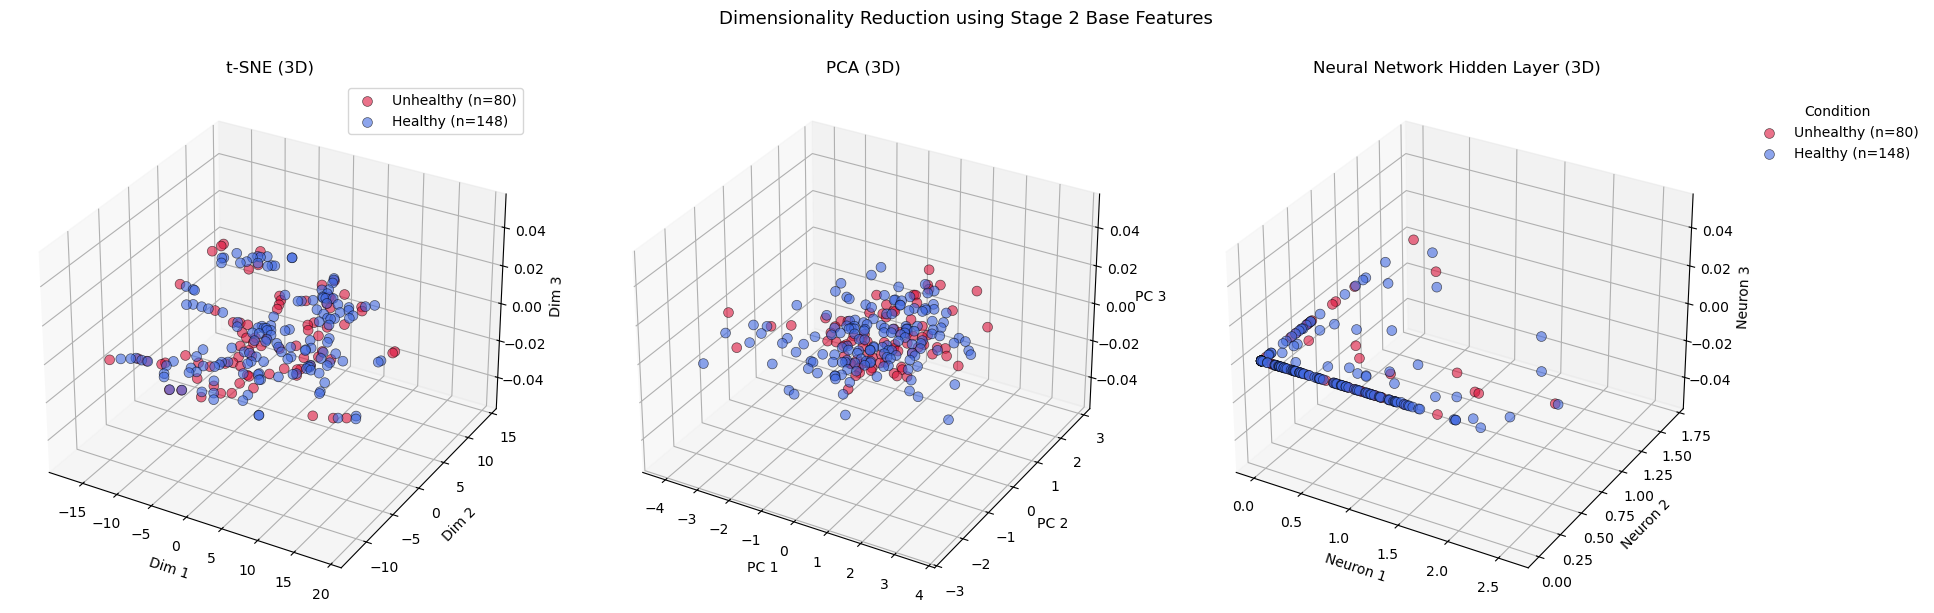

In [9]:
# Stage 2
plot_for_features(X_s2[base_features], title="Dimensionality Reduction using Stage 2 Base Features")

## Visualizing separatability using Features Extracted by Drop Zeros Method

Training accuracy: 0.649


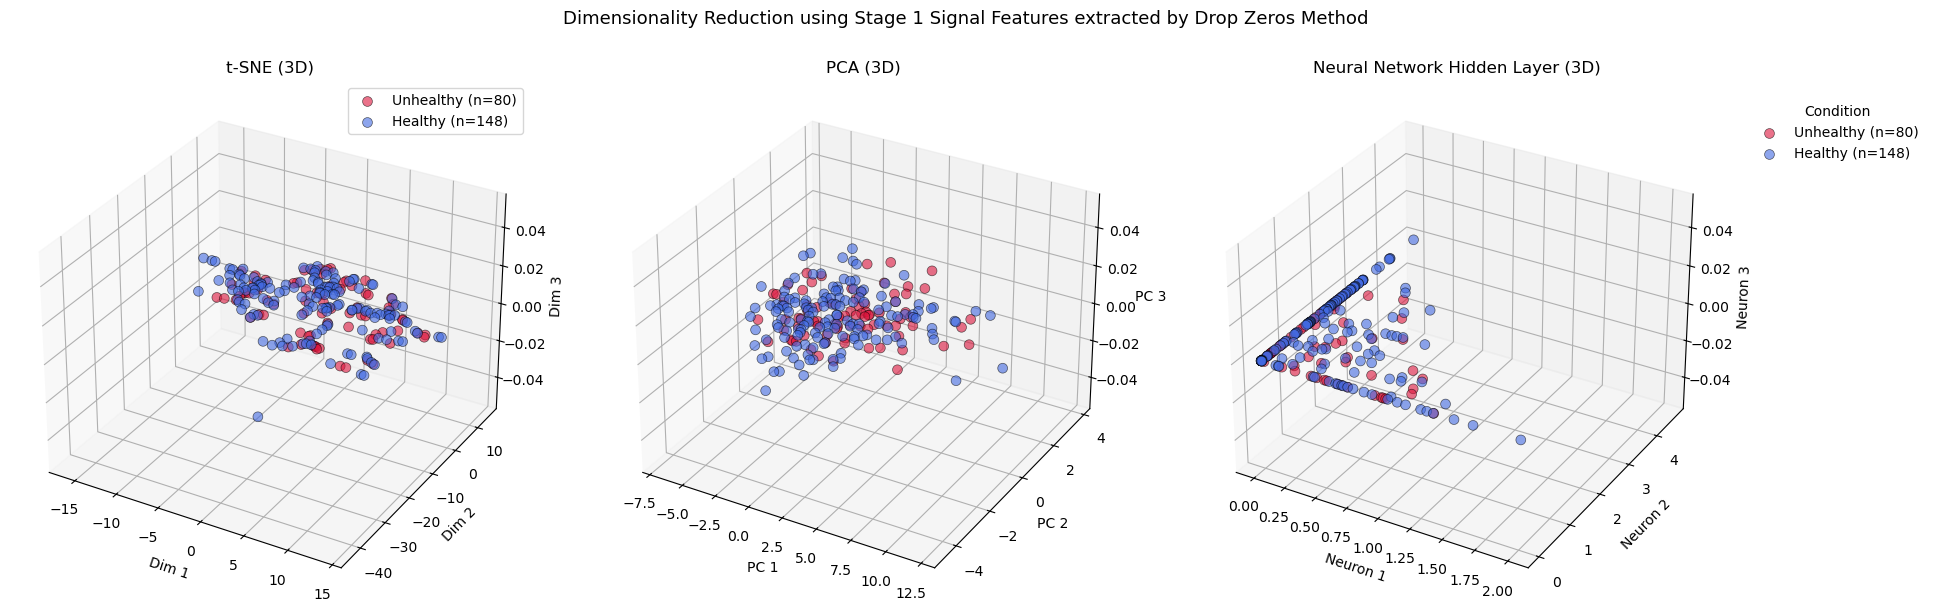

In [10]:
# Stage 1
drop_zeros_features = [col for col in X_s2.columns if col.endswith("drop_zeros")]
plot_for_features(X_s1[drop_zeros_features], title="Dimensionality Reduction using Stage 1 Signal Features extracted by Drop Zeros Method")

Training accuracy: 0.649


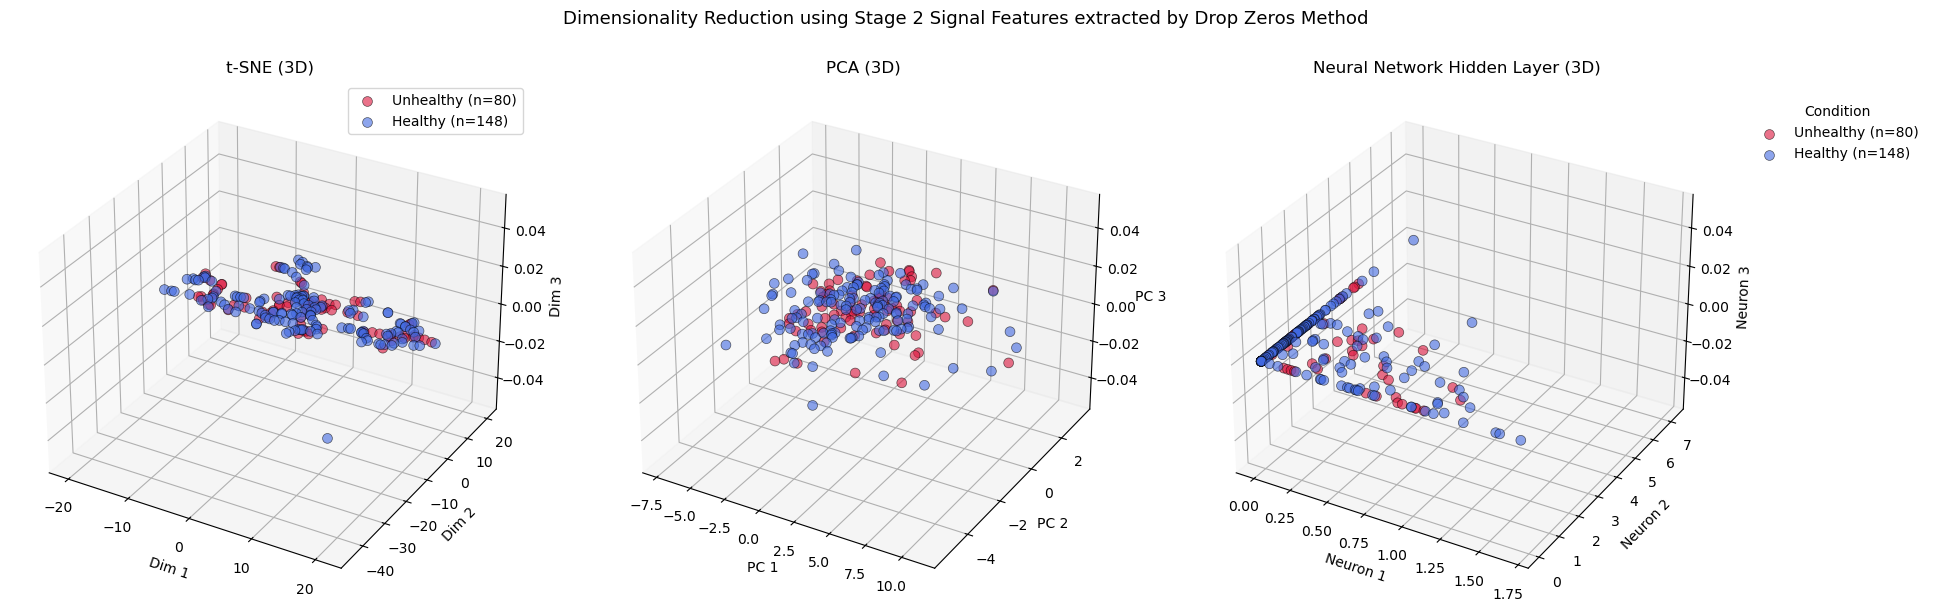

In [11]:
# Stage 2
drop_zeros_features = [col for col in X_s2.columns if col.endswith("drop_zeros")]
plot_for_features(X_s2[drop_zeros_features], title="Dimensionality Reduction using Stage 2 Signal Features extracted by Drop Zeros Method")

## Visualizing separatability using Features Extracted by Autoencoder method

Training accuracy: 0.649


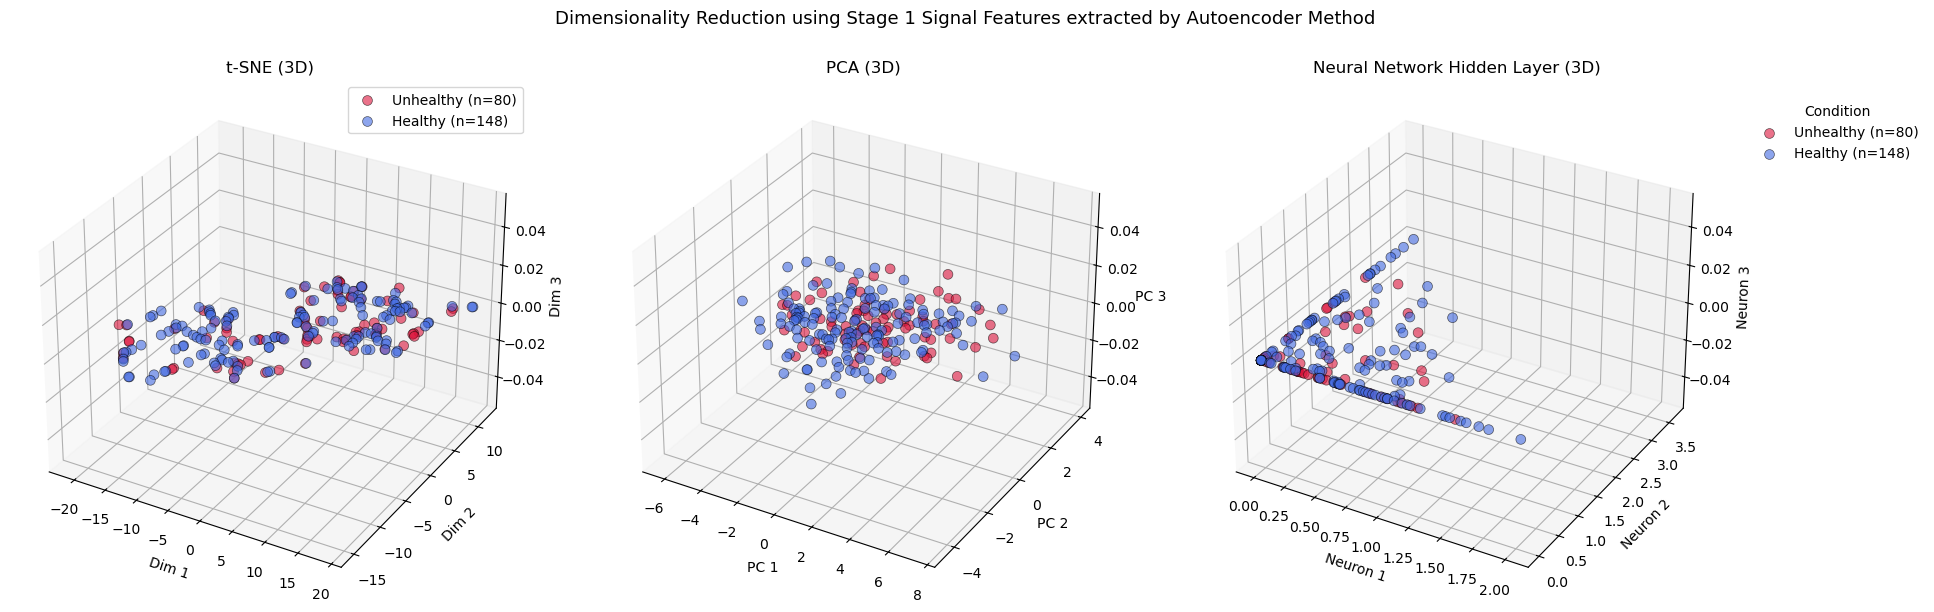

In [12]:
# Stage 1
drop_zeros_ae_features = [col for col in X_s1.columns if col.endswith("drop_long_then_autoencoder")]
plot_for_features(X_s1[drop_zeros_ae_features], title="Dimensionality Reduction using Stage 1 Signal Features extracted by Autoencoder Method")

Training accuracy: 0.649


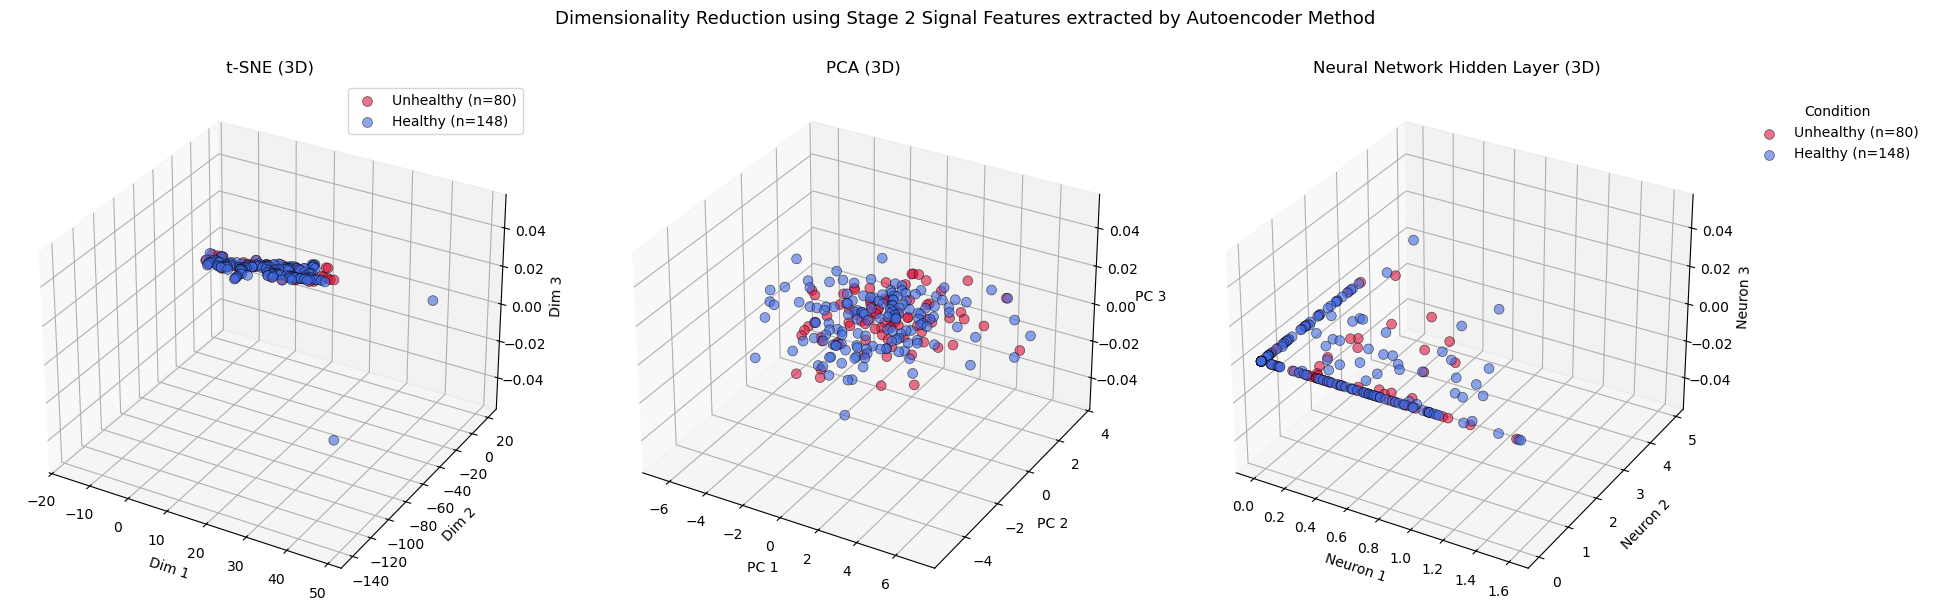

In [13]:
# Stage 2
drop_zeros_ae_features = [col for col in X_s2.columns if col.endswith("drop_long_then_autoencoder")]
plot_for_features(X_s2[drop_zeros_ae_features], title="Dimensionality Reduction using Stage 2 Signal Features extracted by Autoencoder Method")

## Checking Distributions of Signal Features

To evaluate whether the distributions of signal features differ between **healthy** and **unhealthy** samples, three non-parametric tests were applied to every numeric feature. Each test computes a statistic and a p-value that quantify how likely it is that both groups come from the same underlying distribution.

* **Kolmogorov–Smirnov (KS) Test**
    Measures the **maximum absolute difference** between the empirical cumulative distribution functions (CDFs) of two samples.
    $$
    D = \max_x | F_1(x) - F_2(x) |
    $$
    A large $D$ (and small p-value) indicates that the two distributions differ in shape or location.

* **Mann–Whitney U Test**
    Compares whether one distribution tends to produce **larger values** than the other, based on rank sums (a non-parametric alternative to the t-test).
    $$
    U = n_1 n_2 + \frac{n_1 (n_1 + 1)}{2} - R_1
    $$
    where $R_1$ is the sum of ranks for group 1. A low p-value suggests a significant shift in medians between groups.

* **Anderson–Darling k-Sample Test**
    Assesses whether samples come from the **same population**, giving **more weight to differences in the tails** of the distributions.
    The test statistic is computed as
    $$
    A^2 = \frac{1}{k} \sum_{i=1}^{k} \frac{1}{n_i} \sum_{j=1}^{N-1}
    \frac{ \left( N_i H_j - n_i j \right)^2 }{ H_j (1 - H_j) }
    $$
    Higher $A^2$ (and smaller significance level) means stronger evidence that the distributions differ.

A significance threshold of **$\alpha = 0.05$** was used for all tests to identify features with statistically different distributions between healthy and unhealthy samples.


In [14]:
# Select numeric columns
numeric_cols = [
    col for col in stage_1_df.columns
    if any(method in col for method in preprocessing_methods)
]

numeric_cols.extend(["fetal_weight", "weeks", "age", "stage_1_percent", "stage_1_normalized", "stage_2_normalized"])
# Prepare results list
results = []

# Separate groups
group_healthy = stage_1_df[stage_1_df["is_unhealthy"] == 0]
group_unhealthy = stage_1_df[stage_1_df["is_unhealthy"] == 1]

for col in numeric_cols:
    if col == "is_unhealthy":
        continue  # skip the label column itself

    x_healthy = group_healthy[col].dropna()
    x_unhealthy = group_unhealthy[col].dropna()

    # Skip if one group is empty
    if len(x_healthy) == 0 or len(x_unhealthy) == 0:
        continue

    # Kolmogorov–Smirnov
    ks_stat, ks_p = ks_2samp(x_healthy, x_unhealthy)

    # Mann–Whitney U
    u_stat, u_p = mannwhitneyu(x_healthy, x_unhealthy, alternative="two-sided")

    # Anderson–Darling
    ad_result = anderson_ksamp([x_healthy, x_unhealthy])
    ad_stat, ad_sig_level = ad_result.statistic, ad_result.significance_level

    # Store results
    results.append({
        "feature": col,
        "KS_stat": ks_stat, "KS_p": ks_p,
        "MannWhitneyU_stat": u_stat, "MannWhitneyU_p": u_p,
        "AndersonDarling_stat": ad_stat, "AndersonDarling_sig": ad_sig_level,
    })

# Convert to DataFrame
distribution_results_df = pd.DataFrame(results)

# Sort by p-value (KS test as default)
distribution_results_df = distribution_results_df.sort_values(by="KS_p")


/tmp/ipykernel_7074/393526632.py:33: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_result = anderson_ksamp([x_healthy, x_unhealthy])


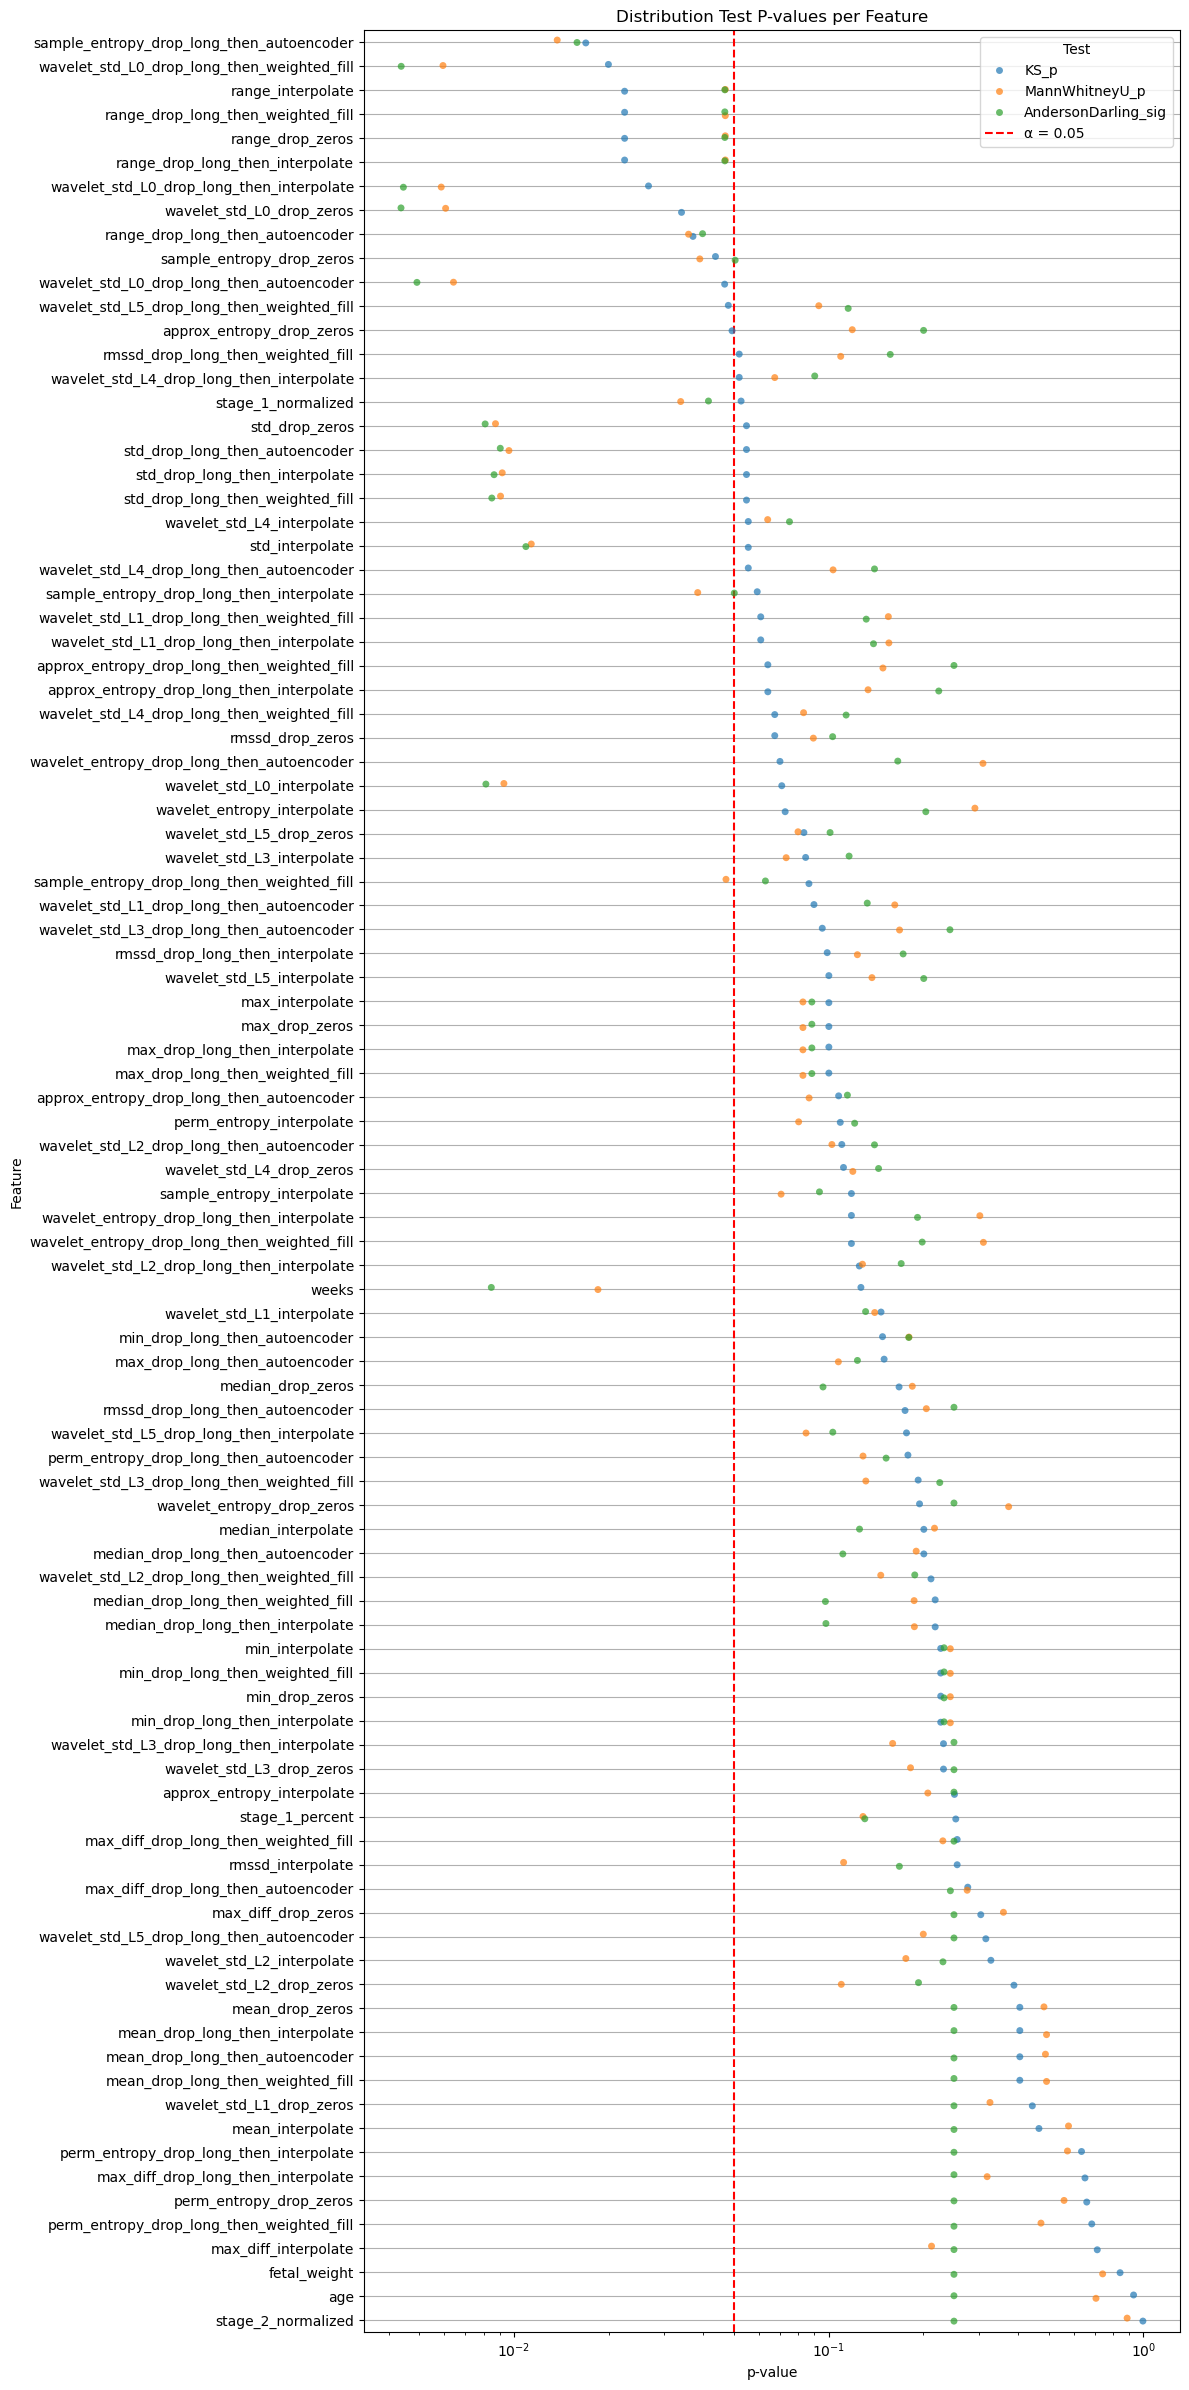

In [15]:
# Melt your result df into long format for plotting
plot_df = distribution_results_df.melt(
    id_vars="feature",
    value_vars=["KS_p", "MannWhitneyU_p", "AndersonDarling_sig"],
    var_name="Test",
    value_name="p_value"
)

# Optional: sort features by KS_p (or another test) for consistency
order = distribution_results_df.sort_values("KS_p")["feature"]

# Set up figure
plt.figure(figsize=(12, 24))  # adjust height for 96 features

sns.stripplot(
    data=plot_df,
    x="p_value",
    y="feature",
    hue="Test",
    order=order,
    dodge=False,
    alpha=0.7
)

# Add significance threshold line
plt.axvline(0.05, color="red", linestyle="--", label="α = 0.05")

plt.title("Distribution Test P-values per Feature")
plt.xlabel("p-value")
plt.ylabel("Feature")
plt.xscale("log")
plt.legend(title="Test")
plt.tight_layout()
plt.grid(axis="y")
plt.show()

* Out of the previous ones, keep the ones that pass all the tests (11)
* Filter correlated features
* Use the final set, training 5 different models to see if they manage to generalize

In [22]:
# Simutaniously pass all the p-values

distribution_results_df[
    (distribution_results_df["KS_p"]<0.05) &
    (distribution_results_df["MannWhitneyU_p"]<0.05) & 
    (distribution_results_df["AndersonDarling_sig"]<0.05)
    ]

,feature,KS_stat,KS_p,MannWhitneyU_stat,MannWhitneyU_p,AndersonDarling_stat,AndersonDarling_sig
45,sample_entropy_drop_long_then_autoencoder,0.210135,0.016908,7092.0,0.013718,3.229636,0.015857
62,wavelet_std_L0_drop_long_then_weighted_fill,0.206419,0.019951,4612.0,0.005947,4.719356,0.004380
39,range_interpolate,0.203716,0.022461,4975.0,0.046917,2.044289,0.046755
37,range_drop_long_then_weighted_fill,0.203716,0.022461,4975.0,0.046917,2.044289,0.046755
38,range_drop_zeros,0.203716,0.022461,4975.0,0.046917,2.044289,0.046755
36,range_drop_long_then_interpolate,0.203716,0.022461,4975.0,0.046917,2.044289,0.046755
61,wavelet_std_L0_drop_long_then_interpolate,0.199662,0.026752,4610.0,0.005871,4.700214,0.004451
63,wavelet_std_L0_drop_zeros,0.193919,0.034061,4615.0,0.006063,4.721031,0.004374
35,range_drop_long_then_autoencoder,0.191892,0.037034,4922.0,0.035861,2.219220,0.039731
60,wavelet_std_L0_drop_long_then_autoencoder,0.186149,0.046702,4624.0,0.006422,4.581964,0.004915


In [41]:
# keep the features

features_to_test = distribution_results_df[
    (distribution_results_df["KS_p"]<0.05) &
    (distribution_results_df["MannWhitneyU_p"]<0.05) & 
    (distribution_results_df["AndersonDarling_sig"]<0.05)
    ]["feature"].values


In [42]:
stage_1_df[features_to_test]

,sample_entropy_drop_long_then_autoencoder,wavelet_std_L0_drop_long_then_weighted_fill,range_interpolate,range_drop_long_then_weighted_fill,range_drop_zeros,range_drop_long_then_interpolate,wavelet_std_L0_drop_long_then_interpolate,wavelet_std_L0_drop_zeros,range_drop_long_then_autoencoder,wavelet_std_L0_drop_long_then_autoencoder
0,0.093379,0.104416,-0.075132,-0.075132,-0.075132,-0.075132,0.105206,0.089771,-0.062464,0.077747
2,0.157453,-0.422142,-0.075132,-0.075132,-0.075132,-0.075132,-0.421852,-0.417778,-0.115206,-0.472125
4,0.207939,-0.969256,-0.484543,-0.484543,-0.484543,-0.484543,-0.969078,-0.953846,-0.454395,-0.983808
6,0.237624,1.162961,-0.361720,-0.361720,-0.361720,-0.361720,1.162783,1.169602,-0.364396,1.133874
8,0.102630,1.254319,0.375220,0.375220,0.375220,0.375220,1.252092,1.245404,0.316693,1.198446
...,...,...,...,...,...,...,...,...,...,...
446,0.259378,0.514818,0.432538,0.432538,0.432538,0.432538,0.517287,0.504295,0.319097,0.498396
448,0.130192,1.691142,1.783594,1.783594,1.783594,1.783594,1.704950,1.605755,1.934487,1.768721
450,0.301205,-0.916994,-1.254236,-1.254236,-1.254236,-1.254236,-0.917000,-0.925463,-1.287488,-0.940471
452,0.214288,-0.056489,-0.148826,-0.148826,-0.148826,-0.148826,-0.055712,-0.077585,-0.122367,-0.068669


In [46]:
corr_matrix_stage_1 = stage_1_df[features_to_test].corr().abs()
corr_matrix_stage_2 = stage_2_df[features_to_test].corr().abs()

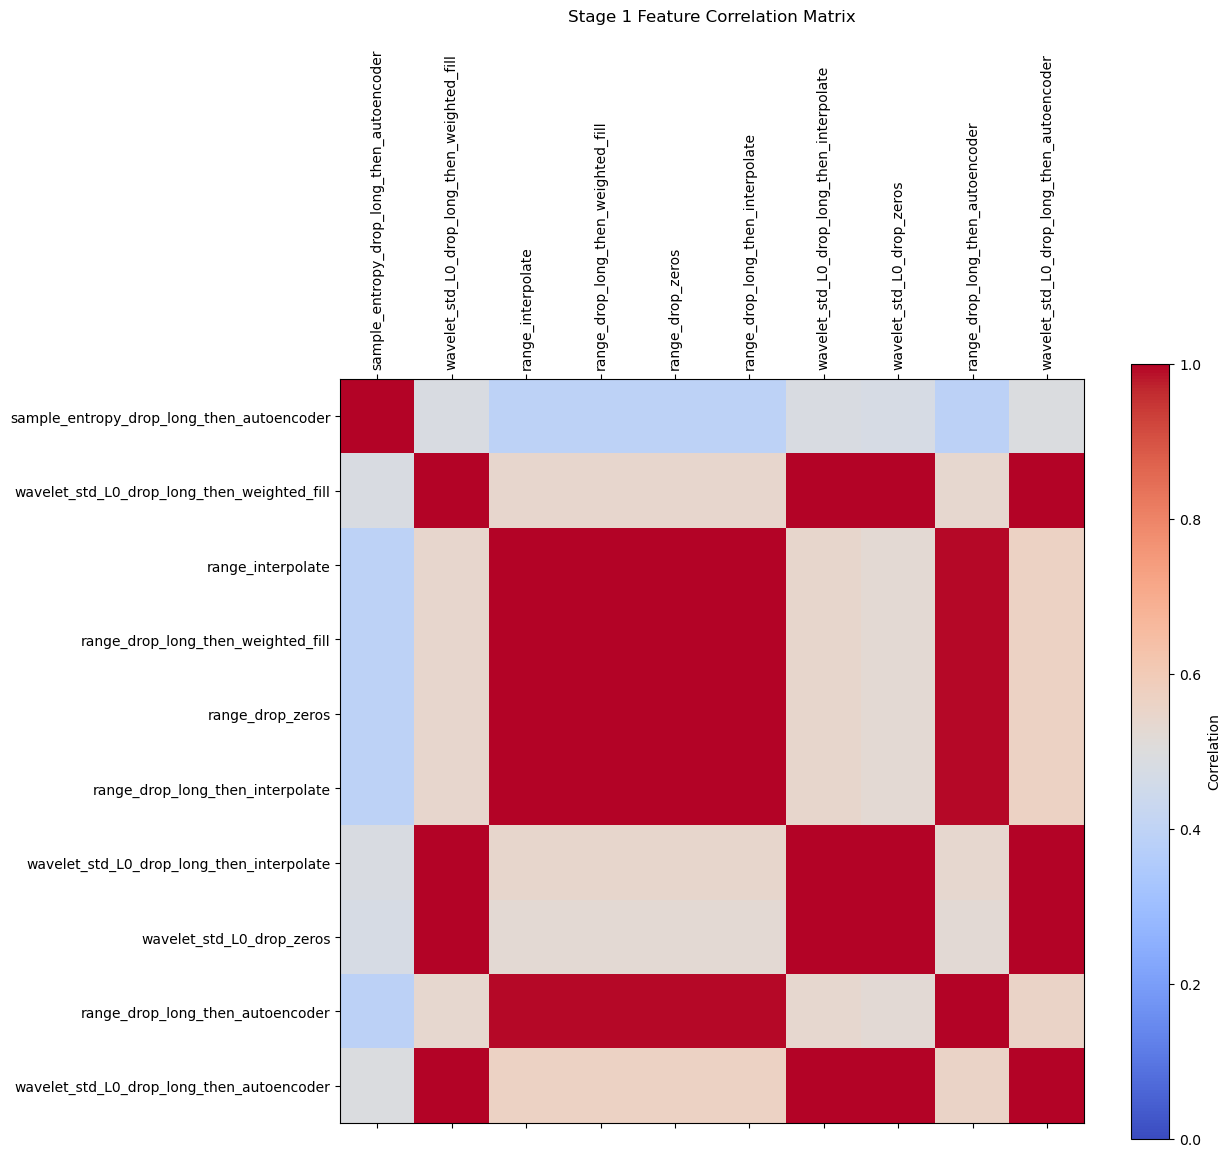

In [110]:
plt.figure(figsize=(12, 10))
plt.matshow(corr_matrix_stage_1, fignum=1, cmap="coolwarm", vmin=0, vmax=1)
plt.colorbar(label="Correlation")

# Set ticks and labels
features = corr_matrix_stage_1.columns
plt.xticks(np.arange(len(features)), features, rotation=90)
plt.yticks(np.arange(len(features)), features)

plt.title("Stage 1 Feature Correlation Matrix", pad=20)
plt.show()

In [105]:
# Function to select uncorrelated features based on order
def select_uncorrelated_features(df, features, threshold=0.8):
    corr_matrix = df[features].corr().abs()
    to_keep = []
    dropped = set()

    # Iterate features in order (already sorted by KS_p)
    for f in features:
        if f in dropped:
            continue
        to_keep.append(f)
        # Drop features that are highly correlated with f
        correlated = corr_matrix.columns[(corr_matrix.loc[f] > threshold) & (corr_matrix.columns != f)]
        dropped.update(correlated)
    return to_keep

# Stage 1
selected_features_stage_1 = select_uncorrelated_features(stage_1_df, features_to_test)
df_stage_1_selected = stage_1_df[selected_features_stage_1]

# Stage 2
selected_features_stage_2 = select_uncorrelated_features(stage_2_df, features_to_test)
df_stage_2_selected = stage_2_df[selected_features_stage_2]

# Output
print("Stage 1 selected features:", selected_features_stage_1)
print("Stage 2 selected features:", selected_features_stage_2)

Stage 1 selected features: ['sample_entropy_drop_long_then_autoencoder', 'wavelet_std_L0_drop_long_then_weighted_fill', 'range_interpolate']
Stage 2 selected features: ['sample_entropy_drop_long_then_autoencoder', 'wavelet_std_L0_drop_long_then_weighted_fill', 'range_interpolate']


In [106]:
X = df_stage_1_selected
y = stage_1_df["is_unhealthy"]

classifiers = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(2), max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "RandomForest": RandomForestClassifier(n_estimators=10, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=10, random_state=42)
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [107]:
results = []

for name, clf in classifiers.items():
    acc_list, bal_acc_list, sens_list, spec_list = [], [], [], []

    for train_idx, test_idx in cv.split(X, y):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        
        # Metrics
        acc = accuracy_score(y_test, y_pred)
        bal_acc = balanced_accuracy_score(y_test, y_pred)
        
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        sens = tp / (tp + fn)
        spec = tn / (tn + fp)
        
        acc_list.append(acc)
        bal_acc_list.append(bal_acc)
        sens_list.append(sens)
        spec_list.append(spec)
    
    results.append({
        "Classifier": name,
        "Accuracy": np.mean(acc_list),
        "Balanced Accuracy": np.mean(bal_acc_list),
        "Sensitivity": np.mean(sens_list),
        "Specificity": np.mean(spec_list)
    })

results_df = pd.DataFrame(results).sort_values("Balanced Accuracy", ascending=False)
results_df



,Classifier,Accuracy,Balanced Accuracy,Sensitivity,Specificity
3,RandomForest,0.662222,0.575934,0.2875,0.864368
4,GradientBoosting,0.666473,0.565029,0.2250,0.905057
2,KNN,0.622802,0.560287,0.3500,0.770575
0,SVM,0.666570,0.536437,0.1000,0.972874
1,MLP,0.662319,0.524583,0.0625,0.986667
